# EDA · Predicción de fallas en flotas con ML

# 1. Instalación y lectura

## 1.1 Instalación del entorno

## 1.2 Configuración

In [1]:
import sys
sys.path.append("..")            # permite importar la carpeta src/ desde notebooks/

import io, contextlib
import pandas as pd
from IPython.display import display

from src import eda              # funciones del EDA (src/eda.py)
from src import preprocesamiento as pp

# Desde la anonimización corregida, las tres fuentes usan el MISMO código de camioneta (VH-01..VH-05).
EQUIVALENCIA = {f"VH-0{i}": f"VH-0{i}" for i in range(1, 6)}

eda.configurar_estilo()
eda.verificar_entorno()

python 3.13.18 | pandas 3.0.5 | numpy 2.5.3 | matplotlib 3.11.2


{'python': '3.13.18',
 'pandas': '3.0.5',
 'numpy': '2.5.3',
 'matplotlib': '3.11.2'}

## 1.3 Lectura de los archivos

In [2]:
f_cons, f_ev = eda.rutas_datos()
hojas_raw = eda.leer_consolidado(f_cons)
eventos_raw = eda.leer_eventos(f_ev)

print("\nConsolidado:", {n: d.shape for n, d in hojas_raw.items()})
print("Detailed Event Report:", eventos_raw.shape)

Consolidado_Hojas_de_Vida_anonimizado.xlsx                   0.0 MB
Detailed Event Report_anonimizado.csv                       59.8 MB



Consolidado: {'Vehículos': (5, 33), 'Mantenimientos': (117, 9), 'Plan de mantenimiento': (105, 11)}
Detailed Event Report: (213221, 30)


# 2. EDA del consolidado de hojas de vida


## 2.1 General (tamaño y tipos de dato)
**Esperado:** Vehículos (5 × 43), Mantenimientos (117 × 8), Plan de mantenimiento (105 × 11).

In [3]:
for nombre, d in hojas_raw.items():
    r = eda.resumen_general(d)
    print(f"\n=== {nombre}: {r['filas']} filas × {r['columnas']} columnas ")
    display(r["tipos"])

# Tipos corregidos y columnas derivadas (es_prev, es_corr, desv_dias, desv_km)
hojas = eda.preparar_consolidado(hojas_raw)
veh, mtto, plan = hojas["Vehículos"], hojas["Mantenimientos"], hojas["Plan de mantenimiento"]


=== Vehículos: 5 filas × 33 columnas 


,dtype,ejemplo
Placa,str,VH-01
Marca,str,NISSAN
Línea,str,FRONTIER
Modelo,int64,2024
Clase,str,CAMIONETA
Carrocería,str,DOBLE CABINA CON
Color,str,PLATA
Combustible,str,DIESEL
Capacidad (kg),int64,758
Capacidad (pasajeros),int64,5



=== Mantenimientos: 117 filas × 9 columnas 


,dtype,ejemplo
Placa,str,VH-01
Fecha,datetime64[us],2024-04-01 00:00:00
Descripción,str,MTTO PREVENTIVO 5.000KM
Tipo,str,Preventivo
Kilometraje acumulado,int64,5203
Orden de servicio,str,OS-007
Costo (COP),int64,598740
Prestador del servicio,str,Taller 01
Orden de servicio formato válido,bool,True



=== Plan de mantenimiento: 105 filas × 11 columnas 


,dtype,ejemplo
Placa,str,VH-01
Año del plan,int64,2024
Rutina,str,"Rutina 5.000 (5, 15, 25, 35… mil km)"
Servicio del plan (km),int64,5000
Km programado,int64,5000
Fecha programada,datetime64[us],2024-06-11 00:00:00
Km ejecutado,float64,5203.0
Fecha ejecutada,datetime64[us],2024-04-01 00:00:00
Texto original programado,str,5.000 KM 11/06/2024
Texto original ejecutado,str,5.203 KM 01/04/2024


 El consolidado contiene tres hojas: 
 * *Vehículos* (5 filas × 43 columnas)
 * *Mantenimientos* (117 × 8) 
 * *Plan de mantenimiento* (105 × 11). 
 
 Los tipos de dato son coherentes con el contenido (las fechas ya vienen como fecha), por lo que solo fue necesario crear columnas derivadas: indicadores de preventivo/correctivo a partir de Tipo y las desviaciones entre lo programado y lo ejecutado en el plan.

## 2.2 Completitud
Nulos por columna, columnas vacías y columnas constantes (sin información para modelar).

In [4]:
for nombre, d in hojas.items():
    r = eda.reporte_completitud(d)
    print(f"\n=== {nombre}")
    print("Columnas vacías (100% nulos):", r["vacias"])
    print("Columnas constantes (1 valor):", r["constantes"])
    display(r["con_nulos"])


=== Vehículos
Columnas vacías (100% nulos): ['Tanque largo', 'Tanque ancho', 'Tanque alto', 'Vencimiento recarga extintor']
Columnas constantes (1 valor): ['Marca', 'Línea', 'Modelo', 'Clase', 'Combustible', 'Capacidad (pasajeros)', 'Conductor / asignación', 'ABS', 'Control de estabilidad (ESP)', 'Neumáticos', 'Iluminación eficiente', 'Suspensión', 'Dirección hidráulica', 'Climatización completa', 'Mantenimiento correctivo', 'Airbag', 'Cinturón de seguridad', 'Apoyacabezas', 'Elementos de protección personal', 'Carrocería (seguridad)', 'Chasis (seguridad)', 'Bluetooth incorporado', 'Mantenimiento preventivo', 'Vigencia SOAT']


,nulos,% nulos,únicos
Tanque largo,5,100.0,0
Tanque ancho,5,100.0,0
Tanque alto,5,100.0,0
Vencimiento recarga extintor,5,100.0,0



=== Mantenimientos
Columnas vacías (100% nulos): []
Columnas constantes (1 valor): ['Prestador del servicio']


'Sin nulos'


=== Plan de mantenimiento
Columnas vacías (100% nulos): []
Columnas constantes (1 valor): ['Observación']


,nulos,% nulos,únicos
Fecha programada,1,1.0,94
Km ejecutado,7,6.7,98
Fecha ejecutada,7,6.7,94
Texto original ejecutado,4,3.8,99
Observación,104,99.0,1
desv_dias,8,7.6,56
desv_km,7,6.7,96


El consolidado presenta una completitud alta. 
* La hoja *Mantenimientos* no tiene nulos en ninguna de sus 8 columnas, incluidas las llaves del análisis (placa, fecha, tipo, kilometraje y costo). 
* En *Vehículos* hay 6 columnas completamente vacías y 32 constantes, consecuencia de que la muestra contiene 5 camionetas de la misma marca y línea; estas 38 columnas se descartan por no aportar variabilidad. 
* En *Plan de mantenimiento* los nulos son pocos y explicables: 7 preventivos programados sin ejecutar (6,7%) y una fecha programada inválida en el origen (31/09/2025). Las columnas `desv_dias` y `desv_km` son derivadas y heredan esos nulos.

## 2.3 Duplicados
Filas repetidas y llaves que deberían ser únicas. Una `Orden de servicio` repetida no es un error: agrupa visitas con preventivo y correctivo.

In [5]:
eda.mostrar_tablas(eda.reporte_duplicados_consolidado(hojas))

filas_completas: {'Vehículos': 0, 'Mantenimientos': 0, 'Plan de mantenimiento': 0}

-- llaves


,llave,filas con llave repetida
0,Vehículos · Placa,0
1,Mantenimientos · Orden de servicio,18
2,Mantenimientos · Placa+Fecha+Descripción,0
3,Plan · Placa+Año+Km programado,0


No se encontraron duplicados en el consolidado: ninguna fila completa se repite y las llaves naturales (`Placa` en Vehículos; Placa+Fecha+Descripción en Mantenimientos; Placa+Año+Km programado en el Plan) son únicas. 

La `Orden de servicio` aparece repetida en 18 filas (9 órdenes), lo que corresponde a visitas al taller en las que se registraron un preventivo y un correctivo bajo la misma orden; por tanto, esta columna identifica la visita y no el registro, y no debe usarse como llave única.

## 2.4 Integridad entre hojas
Que las tres hojas hablen de las mismas camionetas y que lo que el *Plan* dice haber ejecutado exista en *Mantenimientos*.

### 2.4.1 Placas: formato y presencia en cada hoja

In [6]:
eda.mostrar_tablas(eda.integridad_placas(hojas))


-- presencia


,Vehículos,Mantenimientos,Plan de mantenimiento,registros_mtto,filas_plan
VH-01,True,True,True,11,11
VH-02,True,True,True,28,26
VH-03,True,True,True,27,22
VH-04,True,True,True,28,26
VH-05,True,True,True,23,20



-- formato


,formato_invalido,con_espacios
hoja,,
Vehículos,0,0
Mantenimientos,0,0
Plan de mantenimiento,0,0


### 2.4.2 Cruce Mantenimientos ↔ Plan
Cada preventivo ejecutado en el plan debe existir en Mantenimientos (misma placa y fecha) con el mismo km.

In [7]:
r = eda.cruce_mtto_plan(mtto, plan)
display(r["conteo"].to_frame("registros"))
print(f"En ambas: km distinto en {r['n_km_distinto']} de {r['n_ambas']}")
display(r["km_distinto"])
print("Registros sin pareja:")
display(r["sin_pareja"])

,registros
_merge,
en ambas,93
solo en Mantenimientos,6
solo en Plan,5


En ambas: km distinto en 5 de 93


,Placa,Fecha,Kilometraje acumulado,Km ejecutado,dif_km
34,VH-02,2026-05-20,117874.0,115000.0,2874.0
58,VH-04,2024-02-26,4811.0,5000.0,-189.0
80,VH-04,2026-05-15,110862.0,110852.0,10.0
90,VH-05,2024-12-13,34617.0,34167.0,450.0
98,VH-05,2026-01-16,75847.0,71285.0,4562.0


Registros sin pareja:


,Placa,Fecha,Fecha ejecutada,Kilometraje acumulado,Km ejecutado,_merge
4,VH-01,2024-10-04,NaT,25462.0,NaN,left_only
7,VH-01,NaT,2025-10-04,NaN,25462.0,right_only
8,VH-01,NaT,2025-10-20,NaN,40441.0,right_only
9,VH-01,2025-10-22,NaT,40441.0,NaN,left_only
15,VH-02,NaT,2024-06-12,NaN,71834.0,right_only
25,VH-02,2025-06-12,NaT,71834.0,NaN,left_only
65,VH-04,2024-12-02,NaT,41854.0,NaN,left_only
75,VH-04,NaT,2025-12-02,NaN,41954.0,right_only
78,VH-04,NaT,2026-03-27,NaN,104250.0,right_only
79,VH-04,2026-03-28,NaT,104250.0,NaN,left_only


Las 5 placas están presentes en las tres hojas con formato válido. 

En el cruce entre *Mantenimientos* y *Plan*, 93 preventivos coinciden en placa y fecha; de ellos, 5 difieren en kilometraje (entre 10 y 4.562 km), y en al menos dos casos el Plan registra el km nominal en lugar del real. 

De los preventivos sin pareja exacta, 5 corresponden al mismo evento registrado con año equivocado (3 casos) o con 1–2 días de diferencia (2 casos), y 1 preventivo de VH-05 (2025-12-05) no figura en el Plan. 

## 2.5 Análisis específico del consolidado

### 2.5.1 Vehículos
Qué columnas aportan información (varían entre camionetas) y perfil básico de la flota de la muestra.

In [8]:
r = eda.perfil_vehiculos(veh)
print(f"Columnas que varían entre camionetas ({len(r['columnas_que_varian'])}):", r["columnas_que_varian"])
print("Columnas constantes o vacías:", r["n_constantes_o_vacias"])
display(r["perfil"])
display(r["detalle"])

Columnas que varían entre camionetas (5): ['Placa', 'Carrocería', 'Color', 'Capacidad (kg)', 'Fecha expedición de placa']
Columnas constantes o vacías: 28


,Placa,Marca,Línea,Modelo,Clase,Combustible
0,VH-01,NISSAN,FRONTIER,2024,CAMIONETA,DIESEL
1,VH-02,NISSAN,FRONTIER,2024,CAMIONETA,DIESEL
2,VH-03,NISSAN,FRONTIER,2024,CAMIONETA,DIESEL
3,VH-04,NISSAN,FRONTIER,2024,CAMIONETA,DIESEL
4,VH-05,NISSAN,FRONTIER,2024,CAMIONETA,DIESEL


Placa,VH-01,VH-02,VH-03,VH-04,VH-05
Carrocería,DOBLE CABINA CON,DOBLE CABIAN CON PLATAFORMA,PLATAFORMA,PLATAFORMA,DOBLE CABINA
Color,PLATA,BLANCO,BLANCO,BLANCO,BLANCO
Capacidad (kg),758,758,2298,2298,758
Fecha expedición de placa,2023-12-11 00:00:00,2023-12-11 00:00:00,2023-12-11 00:00:00,2024-12-07 00:00:00,2023-12-11 00:00:00


La muestra comprende 5 camionetas Nissan Frontier modelo 2024, clase camioneta y combustible diésel, por lo que la flota es homogénea en marca, línea, año y combustible. Solo cuatro atributos varían entre unidades: carrocería (doble cabina o plataforma), color, capacidad de carga (758 kg en doble cabina y 2.298 kg en plataforma, atributos redundantes entre sí) y fecha de expedición de la placa. 

### 2.5.2 Mantenimientos

#### a) Fechas

In [9]:
r = eda.resumen_fechas_mtto(mtto)
print("Rango:", r["primera"], "→", r["ultima"], "| fechas futuras:", r["fechas_futuras"])
display(r["por_placa"])

Rango: 2024-02-26 → 2026-09-14 | fechas futuras: 0


,primera,ultima,registros
Placa,,,
VH-01,2024-04-01,2026-08-24,11
VH-02,2024-02-29,2026-08-12,28
VH-03,2024-03-06,2026-09-11,27
VH-04,2024-02-26,2026-09-14,28
VH-05,2024-03-14,2026-09-01,23


Los mantenimientos abarcan del 26/02/2024 al 14/09/2026 (≈ 30 meses), sin fechas inválidas ni futuras.

Cada camioneta inicia con su preventivo de ~5.000 km, por lo que el historial cubre toda la vida útil observada sin truncamiento inicial. 

El número de registros difiere entre unidades (11 en VH-01; 23–28 en las demás), reflejo de un uso desigual: VH-01 acumula menos de la mitad del kilometraje de VH-02 y VH-04

#### b) Tipo de mantenimiento y consistencia con la descripción
La Guía 2 define la falla *no programada* como un correctivo a más de 3 días de un preventivo; aquí se ve el `Tipo` crudo.

In [10]:
r = eda.resumen_tipo_mtto(mtto)
display(r["conteo_tipo"].to_frame("registros"))
print("Correctivos / total:", r["pct_correctivos"], "%")
display(r["por_placa"])
print("Consistencia Tipo vs texto de la descripción:")
display(r["consistencia"])

,registros
Tipo,
Preventivo,98
Correctivo,19


Correctivos / total: 16.2 %


Tipo,Correctivo,Preventivo,All
Placa,,,
VH-01,1,10,11
VH-02,4,24,28
VH-03,6,21,27
VH-04,4,24,28
VH-05,4,19,23
All,19,98,117


Consistencia Tipo vs texto de la descripción:


Descripción (texto),dice CORRECTIVO,dice PREVENTIVO
Tipo (columna),,
Correctivo,19,0
Preventivo,0,98


La hoja *Mantenimientos* contiene 117 registros: 98 preventivos y 19 correctivos (16,2%). La columna `Tipo` no tiene nulos y es consistente en el 100% de los casos con el texto de la descripció. 

El número de correctivos es bajo lo que puede deberse a que la muestra corresponde a camionetas nuevas o a un subregistro de correctivos, y debe validarse con el responsable de flota

#### c) Orden cronológico y kilometraje
El km acumulado no debe retroceder por camioneta. Los intervalos entre preventivos alimentan el ciclo de ~5.000 km.

In [11]:
r = eda.intervalos_mtto(mtto)
print("Archivo en orden cronológico por placa:", r["archivo_en_orden"])
print("Retrocesos de km:", r["retrocesos_km"], "| mismo km que el registro anterior (d_km = 0):", r["km_repetido"])
display(r["sin_avance"])
print("Kilometraje acumulado por camioneta:")
display(r["km_por_placa"])
print("Intervalo entre preventivos consecutivos (solo preventivos):")
display(r["entre_preventivos"])

Archivo en orden cronológico por placa: True
Retrocesos de km: 0 | mismo km que el registro anterior (d_km = 0): 18


,Placa,Fecha,Descripción,Kilometraje acumulado,d_km,d_dias
8,VH-01,2025-10-22,MTTO CORRECTIVO CAMBIO ACEITE DE CAJA,40441,0.0,0.0
21,VH-02,2025-03-07,MTTO CORRECTIVO BUJE BARRA ESTABILIZADORA,58530,0.0,0.0
27,VH-02,2025-08-22,MTTO CORRECTIVO CAMBIO ACEITE CAJA,81818,0.0,0.0
29,VH-02,2025-09-18,MTTO CORRECTIVO KIT PASTILLAS FRENO TRASERO,85451,0.0,0.0
35,VH-02,2026-04-08,MTTO CORRECTIVO MANGERAS DE ADMISIÓN,112318,0.0,0.0
46,VH-03,2024-12-30,MTTO CORRECTIVO ALARMA DE REVERSA,36529,0.0,0.0
50,VH-03,2025-05-07,"MTTO CORRECTIVO KIT PASTILLAS,DELANTERAS Y TRASERAS,AMORTIGUADORES TRASEROS",51107,0.0,0.0
58,VH-03,2026-02-05,MTTO CORRECTIVO KIT PASTILLAS Y DISCO FRENO DELANTERO,82389,0.0,8.0
60,VH-03,2026-03-10,MTTO CORRECTIVO BATERIA,86317,0.0,0.0
65,VH-03,2026-09-11,MTTO CORRECTIVO KIT Y JUEGO DE PASTILLAS FRENO TRASERO,107850,0.0,1.0


Kilometraje acumulado por camioneta:


,min,max,count
Placa,,,
VH-01,5203,49038,11
VH-02,4756,130247,28
VH-03,4622,107850,27
VH-04,4811,127638,28
VH-05,4738,97960,23


Intervalo entre preventivos consecutivos (solo preventivos):


,d_km,d_dias
count,93.0,93.0
mean,5254.0,49.0
std,1013.0,26.0
min,3054.0,9.0
25%,4784.0,36.0
50%,5356.0,43.0
75%,5707.0,50.0
max,10693.0,182.0


Los registros están en orden cronológico por camioneta y el kilometraje acumulado no presenta retrocesos. Los 18 casos en que el km no cambia respecto al registro anterior son todos correctivos, algunos con hasta 8 días de diferencia, lo que indica que el km de un correctivo se hereda del preventivo cercano y no corresponde a la lectura del odómetro al momento de la falla; por tanto, para ubicar fallas en el ciclo deberá usarse la telemetría. 

El intervalo entre preventivos consecutivos tiene mediana de 5.356 km y 43 días (rango intercuartílico 4.784–5.707 km), es decir, los preventivos se ejecutan en promedio ~350 km después de los 5.000 km nominales, lo que equivale a ~125 km/día 

#### d) Costos

Costo nulo: 0 | cero: 0 | negativo: 0


,count,mean,std,min,25%,50%,75%,max
Tipo,,,,,,,,
Correctivo,19.0,1256462.0,1289961.0,62690.0,517282.0,690864.0,1791764.0,4995788.0
Preventivo,98.0,1010633.0,487410.0,398852.0,576750.0,888990.0,1279708.0,2197511.0


,total COP
Tipo,
Correctivo,23872782
Preventivo,99042058


Correctivos como % del gasto registrado: 19.4 %
Costos atípicos (regla IQR por tipo): 1


,Placa,Fecha,Descripción,Tipo,Costo (COP)
115,VH-05,2026-07-15,"MTTO CORRECTIVO DISCOS, PASTILLAS Y ZAPATAS",Correctivo,4995788


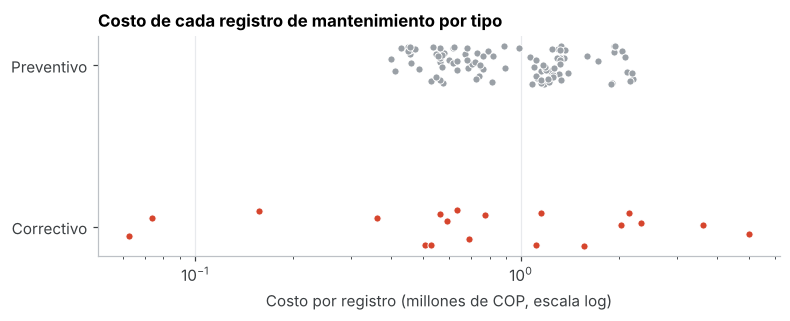

In [12]:
r = eda.resumen_costos(mtto)
print(f"Costo nulo: {r['nulos']} | cero: {r['ceros']} | negativo: {r['negativos']}")
display(r["por_tipo"])
display(r["total_por_tipo"])
print("Correctivos como % del gasto registrado:", r["pct_correctivos_del_gasto"], "%")
print("Costos atípicos (regla IQR por tipo):", r["n_atipicos"])
display(r["atipicos"])
eda.grafico_costos(mtto)

Los costos no presentan nulos, ceros ni valores negativos. Los preventivos suman $99,0 M (mediana $0,89 M, rango $0,40–2,20 M) y los correctivos $23,9 M (mediana $0,69 M, rango $62.690–$4,99 M), de modo que los correctivos representan cerca del 19% del gasto registrado

 El único valor atípico (VH-05, 2026-07-15, discos, pastillas y zapatas, $4,99 M) corresponde a una reparación de frenos de alto costo y se conserva

#### e) Orden de servicio y prestador

In [13]:
eda.mostrar_tablas(eda.resumen_orden_prestador(mtto))

os_nulas: 0
os_unicas: 108
total_registros: 117
formato_OS_NNN: True

-- prestador_por_tipo


Tipo,Correctivo,Preventivo,All
Prestador del servicio,,,
Taller 01,19,98,117
All,19,98,117


La `Orden de servicio` no tiene nulos y sigue el formato `OS-NNN` en todos los registros; hay 108 órdenes únicas en 117 registros, porque 9 órdenes agrupan un preventivo y un correctivo de la misma visita. Los registros se distribuyen entre tres prestadores: Taller-03 atiende el 43% de los registros y el 53% de los correctivos (20% de sus servicios son correctivos, frente a ~13–14% en los otros dos talleres)

#### f) Visitas con más de un registro el mismo día y regla de los 3 días
Afecta la etiqueta de falla no programada: un correctivo hecho en la misma visita de un preventivo es programado.

In [14]:
r = eda.resumen_visitas(mtto, umbral_dias=3)
print("Visitas (placa+fecha):", r["n_visitas"], "| con más de un registro:", r["visitas_con_mas_de_un_registro"])
display(r["tipos_de_visita"])
print(f"Correctivos: {len(r['correctivos'])} | no programados (> 3 días de un preventivo): {r['n_no_programados']}")
display(r["correctivos"])
print("Sensibilidad al umbral:")
display(r["sensibilidad"])

Visitas (placa+fecha): 104 | con más de un registro: 13


,visitas
tipos,
Preventivo,85
Correctivo + Preventivo,13
Correctivo,6


Correctivos: 19 | no programados (> 3 días de un preventivo): 3


,Placa,Fecha,Descripción,Kilometraje acumulado,min_dias_a_preventivo,no_programado
0,VH-01,2025-10-22,MTTO CORRECTIVO CAMBIO ACEITE DE CAJA,40441,0,False
1,VH-02,2025-03-07,MTTO CORRECTIVO BUJE BARRA ESTABILIZADORA,58530,0,False
2,VH-02,2025-08-22,MTTO CORRECTIVO CAMBIO ACEITE CAJA,81818,0,False
3,VH-02,2025-09-18,MTTO CORRECTIVO KIT PASTILLAS FRENO TRASERO,85451,0,False
4,VH-02,2026-04-08,MTTO CORRECTIVO MANGERAS DE ADMISIÓN,112318,0,False
5,VH-03,2024-12-30,MTTO CORRECTIVO ALARMA DE REVERSA,36529,0,False
6,VH-03,2025-05-07,"MTTO CORRECTIVO KIT PASTILLAS,DELANTERAS Y TRASERAS,AMORTIGUADORES TRASEROS",51107,0,False
7,VH-03,2025-07-30,MTTO CORRECTIVO PLUMILLAS,60611,29,True
8,VH-03,2026-02-05,MTTO CORRECTIVO KIT PASTILLAS Y DISCO FRENO DELANTERO,82389,8,True
9,VH-03,2026-03-10,MTTO CORRECTIVO BATERIA,86317,0,False


Sensibilidad al umbral:


,umbral (días),no programados,de correctivos
0,0,6,19
1,1,3,19
2,3,3,19
3,5,2,19
4,7,2,19
5,10,1,19
6,30,0,19


Las 117 filas corresponden a 104 visitas (placa + fecha); 13 incluyen un preventivo y un correctivo el mismo día, 85 solo preventivo y 6 solo correctivo. 

Solo 3 de los 19 correctivos (16%) resultan no programados, frente al 70% reportado para la flota; el 84% restante se realizó en la visita del preventivo o a un día de ella. 

#### g) Línea de tiempo por camioneta

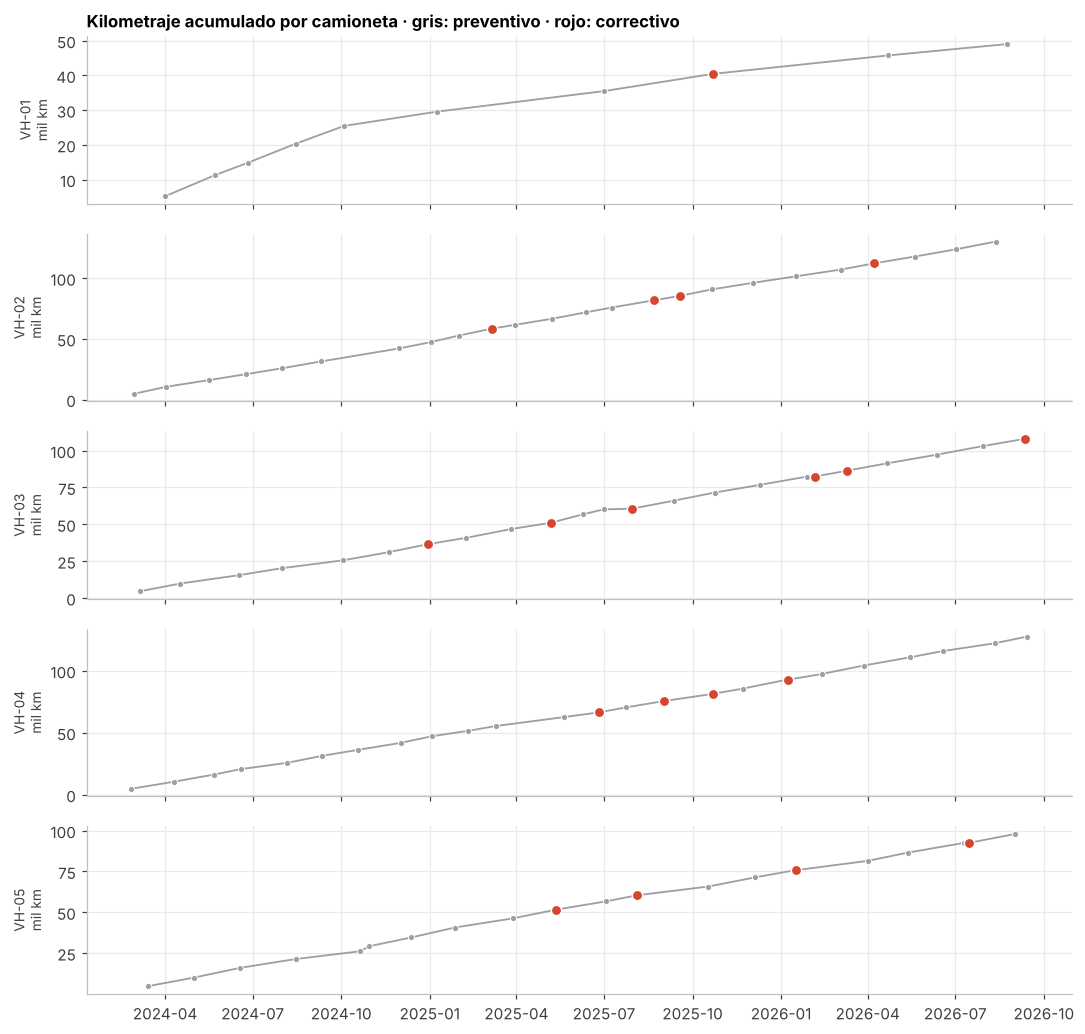

In [15]:
eda.grafico_linea_tiempo_mtto(mtto)

El kilometraje acumulado de VH-02 a VH-05 crece de forma casi lineal (~45.000–50.000 km/año), mientras que VH-01 cambia de régimen de uso tras octubre de 2024 y presenta un tramo de ~6 meses sin registros, lo que debe tenerse en cuenta en el pronóstico de km/día. 

Los correctivos se ubican sobre la línea de kilometraje, pegados a un preventivo, lo que confirma que su km se hereda del preventivo cercano. 

Ninguna camioneta registra correctivos antes de ~36.500 km, lo que sugiere que el riesgo de falla aumenta con el kilometraje acumulado y que el km es un predictor candidato.

# 3. EDA del Detailed Event Report (telemetría GPS)

## 3.1 General (tamaño y tipos de dato)

In [16]:
r = eda.resumen_general(eventos_raw)
print(f"Filas: {r['filas']:,} | columnas: {r['columnas']} | memoria: {r['memoria_mb']:.0f} MB")
display(r["tipos"])

Filas: 213,221 | columnas: 30 | memoria: 257 MB


,dtype,ejemplo
AssetSiteName,str,Contrato D (Llanos Orientales)
ReportGroup,str,"TODOS, Todos Menos VH-06"
AssetExtra,str,VH-04
Asset2SiteName,str,Contrato D (Llanos Orientales)
Asset2ReportGroup,float64,None
AssetName2,str,Conductor 07
FleetNumber,float64,None
TripID,str,#Error
EventKey,int64,3490056536553548824
EventDescription,str,EC Ralenti


**Corrección de tipos.** Se trabaja sobre una copia `ev`:
- `StartOdo` y `EventValue` vienen como texto con coma de miles (`68,784.40`) → se convierten a número.
- Fecha y hora vienen separadas (`dd/mm/aaaa` + `hh:mm:ss`) → se combinan en `inicio` y `fin`.
- `TotalDuration` viene como texto `hh:mm:ss` → se convierte a segundos (`duracion_s`).

In [17]:
ev, info = eda.convertir_tipos_eventos(eventos_raw)
for k, v in info.items():
    print(f"{k}: {v}")

no_nulos_antes: {'StartOdo': 213221, 'EventValue': 21532}
no_nulos_despues: {'StartOdo': 213221, 'EventValue': 21532}
fechas_inicio_invalidas: 0
fechas_fin_invalidas: 0
duraciones_invalidas: 0
rango: 2025-09-30 19:01:49 → 2026-11-13 23:43:09


El *Detailed Event Report* contiene 213.221 eventos y 44 columnas, con un registro por evento de la plataforma GPS. Varias columnas requieren corrección de tipo: `StartOdo` y `EventValue` están almacenados como texto con separador de miles, y las fechas, horas y duraciones están en columnas de texto separadas (`dd/mm/aaaa`, `hh:mm:ss`)

## 3.2 Completitud
Nulos por columna, columnas vacías y constantes, valores centinela y lecturas de voltaje en cero.

In [18]:
r = eda.reporte_completitud(ev, excluir_constantes=True)
print("Columnas vacías (100% nulos):", r["vacias"])
print("Columnas constantes (1 solo valor):", r["constantes"])
print("Columnas con algún nulo pero informativas:")
display(r["con_nulos"])
print("Valores centinela ('#Error', '[UNKNOWN]'):")
display(eda.valores_centinela(ev))
print("Voltaje en 0 mV:", eda.voltaje_en_cero(ev))

Columnas vacías (100% nulos): ['Asset2ReportGroup', 'FleetNumber', 'RoadSpeedLimit', 'EventLocation', 'F_StartRegion', 'F_EndRegion']
Columnas constantes (1 solo valor): ['AssetSiteName', 'ReportGroup', 'TripID', 'TimeZone', 'TotalOccurs', 'MeasurementUnits', 'EndOdo', 'FuelUsed', 'DistanceCalculatedFromOdo']
Columnas con algún nulo pero informativas:


,nulos,% nulos,únicos
EventValue,191689,89.9,87


Valores centinela ('#Error', '[UNKNOWN]'):


,centinelas,% de filas
columna,,
TripID,213221,100.0


Voltaje en 0 mV: {'lecturas_voltaje': 21532, 'en_cero': 658, '% en_cero': 3.1}


El archivo anonimizado conserva 30 de las 44 columnas originales: la anonimización eliminó la placa en texto, los identificadores internos, las coordenadas, las calles, los municipios y las geocercas (ver `docs/log_anonimizacion.csv`). De las 30, 15 no aportan información: están completamente vacías o contienen un único valor (entre ellas `TripID`, siempre `#Error`, y `EndOdo`, `FuelUsed` y `DistanceCalculatedFromOdo`, siempre cero). Los nulos de las columnas restantes son mayormente estructurales: `EventValue` solo existe en los eventos de voltaje (10,1 % de las filas). La región figura como "Sin dato" en el 18,8 % de los eventos (sin posición GPS). Finalmente, 658 lecturas de voltaje (3,1 %) valen 0 mV y se tratarán como faltantes.

## 3.3 Duplicados

In [19]:
eda.mostrar_tablas(eda.reporte_duplicados_eventos(ev))
print("\nCortes de red registrados como GSM y GPRS a la vez:")
eda.mostrar_tablas(eda.cortes_red_gemelos(ev))

filas_completas: 0
EventKey_repetido: 0
repetidos_camioneta_inicio_tipo: 0
repetidos_camioneta_inicio_fin_tipo_odo: 0

Cortes de red registrados como GSM y GPRS a la vez:
cortes_distintos: 35032
registrados_como_gsm_y_gprs: 11295
eventos_de_red: 46327


No se encontraron duplicados: ninguna fila completa se repite, `EventKey` es único en los 213.221 registros y no existen dos eventos del mismo tipo con igual camioneta e instante de inicio

## 3.4 Confidencialidad de la anonimización
**Por qué:** el repositorio es público y la Guía 3 (riesgo 8.2.1) exige anonimizar placas, conductores y contratos. Se verifica, sin imprimir valores, que ninguna columna conserve un texto con formato de placa. La anonimización (`src/anonimizar.py`) aplica una política explícita por columna y bloquea la exportación si encuentra placas, nombres, cédulas o nombres reales; el detalle de qué se hizo con cada columna está en `docs/log_anonimizacion.csv`.

In [20]:
r = eda.revisar_confidencialidad(ev)
print("Filas con texto en formato de placa real:", r["filas_con_placa_real"], "| columnas:", r["columnas_con_placa"])
print("Códigos de camioneta:", r["codigos_camioneta"])

Filas con texto en formato de placa real: 0 | columnas: []
Códigos de camioneta: ['VH-01', 'VH-02', 'VH-03', 'VH-04', 'VH-05']


La verificación no encuentra ningún texto con formato de placa en el archivo anonimizado. Una versión anterior del archivo conservaba la placa real en `AssetName` y usaba códigos distintos en cada fuente; la anonimización se rehízo con una sola tabla de códigos para las tres fuentes y con eliminación de coordenadas, calles, municipios, geocercas e identificadores internos.

## 3.5 Análisis específico del Detailed Event Report

### 3.5.1 Cobertura temporal por camioneta
Rango observado, días con eventos y huecos. Los huecos largos pueden ser camioneta parada o falla de transmisión, y afectan la continuidad de la serie de voltaje.

,primer_evento,ultimo_evento,eventos,dias_con_eventos,dias_en_rango,% dias con eventos
AssetExtra,,,,,,
VH-01,2025-09-30 23:28:52,2026-11-13 14:16:28,32167,398,410,97.1
VH-02,2025-10-01 04:51:41,2026-11-13 18:15:22,46586,409,409,100.0
VH-03,2025-09-30 19:19:37,2026-11-13 16:50:36,48898,400,410,97.6
VH-04,2025-09-30 19:01:49,2026-11-13 23:43:09,61629,408,410,99.5
VH-05,2025-09-30 21:09:06,2026-11-02 17:50:05,23941,250,399,62.7


Hueco más largo sin eventos (días) por camioneta:


,dias
AssetExtra,
VH-01,3
VH-02,1
VH-03,5
VH-04,3
VH-05,52


Hueco de VH-05: {'desde': datetime.date(2026, 6, 17), 'hasta': datetime.date(2026, 8, 8), 'dias': 52}


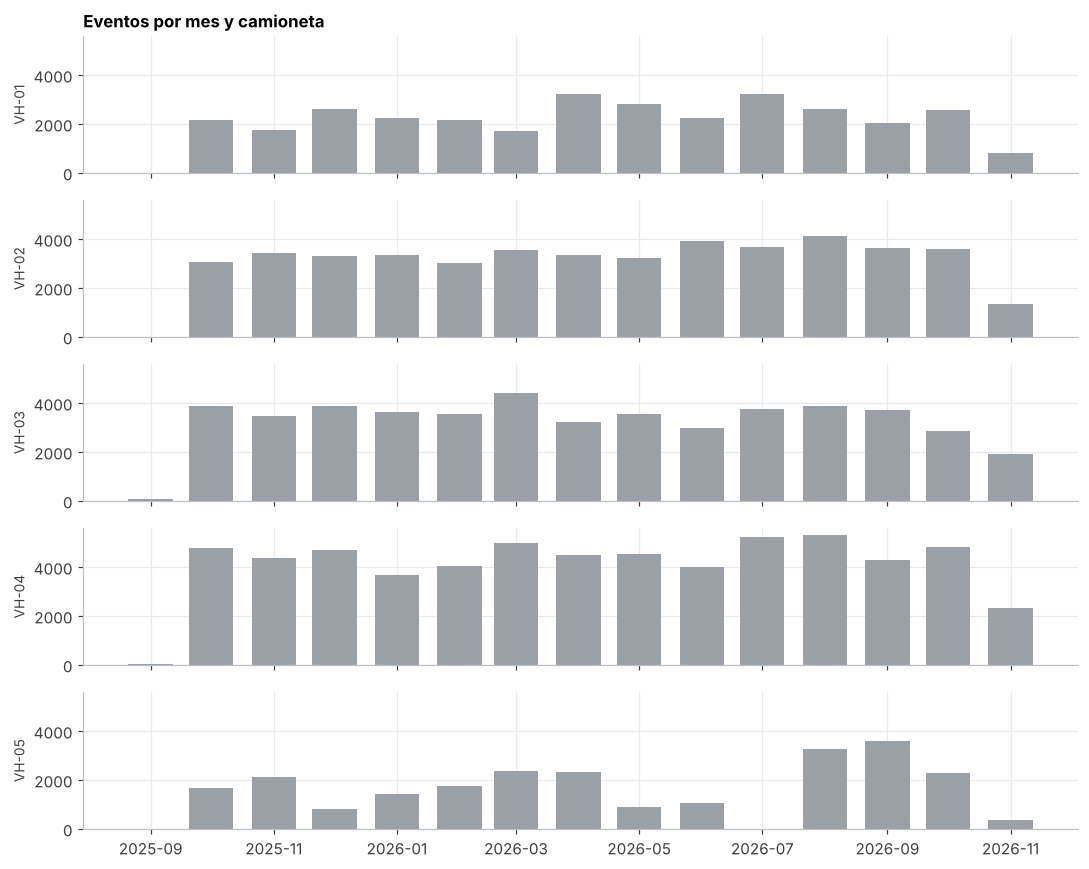

In [21]:
cov = eda.cobertura_temporal(ev)
display(cov["cobertura"])
print("Hueco más largo sin eventos (días) por camioneta:")
display(cov["hueco_max_dias"])
print("Hueco de VH-05:", eda.hueco_mas_largo(ev, "VH-05"))
eda.grafico_eventos_mensuales(ev)

La telemetría abarca del 30/09/2025 al 13/11/2026 (410 días). Cuatro de las cinco camionetas registran eventos en el 97–100% de los días, con huecos máximos de 1 a 5 días. VH-05 es la excepción: solo tiene eventos en el 63% de los días, termina el 02/11/2026 y presenta un hueco de 52 días (17/06 a 08/08/2026), con actividad casi nula entre mayo y julio de 2026; no es posible distinguir entre inactividad del vehículo y fallo del equipo, por lo que debe validarse con el responsable de flota

### 3.5.2 Catálogo de eventos
Tipos de evento y, dentro de ellos, los que describen el estado eléctrico del vehículo (la base para estudiar la batería).

In [22]:
r = eda.catalogo_eventos(ev)
display(r["catalogo"])
print("Eventos por tipo de evento y camioneta:")
display(r["por_camioneta"])

b = eda.resumen_eventos_bateria(ev)
print(f"\nEventos relacionados con la batería: {b['eventos']:,} ({b['% del total']}% del total)")
display(b["tabla"])

EventType,Detalles,Notificar,All,% del total
EventDescription,,,,
All,213060,161,213221,100.0
EC Ralenti,138785,0,138785,65.1
DLP: No GSM Coverage,23397,0,23397,11.0
DLP: No GPRS Coverage,22930,0,22930,10.8
P.D.C Voltaje Bateria Promedio,18889,0,18889,8.9
EC Ralenti excesivo,6416,0,6416,3.0
DLP: Alerta Voltaje Batería (IGNON)<10VPro<5s,2299,0,2299,1.1
DLP: Alerta Voltaje Bajo Batería (IGNON)<9.5VPro,344,0,344,0.2
OBC unit reset,0,90,90,0.0


Eventos por tipo de evento y camioneta:


AssetExtra,VH-01,VH-02,VH-03,VH-04,VH-05,All
EventDescription,,,,,,
DLP: Alerta Voltaje Bajo Batería (IGNON)<9.5VPro,275,2,17,50,0,344
DLP: Alerta Voltaje Batería (IGNON)<10VPro<5s,584,306,482,859,68,2299
DLP: Desconexion Bateria,29,11,25,4,2,71
DLP: No GPRS Coverage,5952,4914,5020,6363,681,22930
DLP: No GSM Coverage,4926,4945,4201,5973,3352,23397
EC Ralenti,15851,30962,33050,41575,17347,138785
EC Ralenti excesivo,731,1699,1816,1500,670,6416
OBC unit reset,32,11,32,5,10,90
P.D.C Voltaje Bateria Promedio,3787,3736,4255,5300,1811,18889



Eventos relacionados con la batería: 21,693 (10.2% del total)


AssetExtra,VH-01,VH-02,VH-03,VH-04,VH-05,All
EventDescription,,,,,,
P.D.C Voltaje Bateria Promedio,3787,3736,4255,5300,1811,18889
DLP: Alerta Voltaje Batería (IGNON)<10VPro<5s,584,306,482,859,68,2299
DLP: Alerta Voltaje Bajo Batería (IGNON)<9.5VPro,275,2,17,50,0,344
DLP: Desconexion Bateria,29,11,25,4,2,71
OBC unit reset,32,11,32,5,10,90
All,4707,4066,4811,6218,1891,21693


El archivo contiene 9 tipos de evento, de los cuales 5 describen el estado eléctrico del vehículo y constituyen la base para reconstruir el comportamiento de la batería en el tiempo: lecturas periódicas de voltaje promedio (18.889), alertas por voltaje inferior a 10 V (2.299) y a 9,5 V (344), desconexiones de batería (71) y reinicios de la unidad (90). 

En conjunto suman 21.693 eventos (10,2% del total) y hay densidad suficiente para seguir cada camioneta en el tiempo (entre ~1.800 y ~5.300 lecturas de voltaje por camioneta). El resto de los eventos son ralentí (68,1%) y pérdida de cobertura GSM/GPRS (21,8%), que pueden servir como variables de contexto pero no describen la batería directamente. 

El comportamiento difiere mucho entre camionetas: VH-01 concentra el 80% de las alertas por debajo de 9,5 V y la mayor cantidad de desconexiones (29); VH-03 y VH-01 acumulan además el mayor número de reinicios (32 cada una); y VH-05 casi no presenta alertas, pero también tiene menos lecturas y un hueco de actividad de 52 días

### 3.5.3 Duración de los eventos
Duraciones de varias horas o días son atípicas y distorsionan sumas (por ejemplo, horas de ralentí o de falta de cobertura).

,count,mean,std,min,50%,99%,max
EventDescription,,,,,,,
DLP: Alerta Voltaje Bajo Batería (IGNON)<9.5VPro,344.0,107.0,536.0,0.0,3.0,3092.0,4927.0
DLP: Alerta Voltaje Batería (IGNON)<10VPro<5s,2299.0,0.0,1.0,0.0,0.0,4.0,4.0
DLP: Desconexion Bateria,71.0,0.0,0.0,0.0,0.0,0.0,0.0
DLP: No GPRS Coverage,22930.0,3808.0,7493.0,0.0,407.0,29059.0,259241.0
DLP: No GSM Coverage,23397.0,3656.0,7370.0,0.0,265.0,28594.0,259241.0
EC Ralenti,138785.0,66.0,244.0,0.0,10.0,973.0,20868.0
EC Ralenti excesivo,6416.0,503.0,814.0,0.0,233.0,3879.0,20568.0
OBC unit reset,90.0,0.0,0.0,0.0,0.0,0.0,0.0
P.D.C Voltaje Bateria Promedio,18889.0,38.0,351.0,0.0,4.0,679.0,15569.0


Eventos > 1 h: 13829 | > 24 h: 35 | duración cero: 24023 | fin < inicio: 0


,AssetExtra,inicio,EventDescription,duracion_s
13106,VH-01,2025-10-26 15:28:12,DLP: No GSM Coverage,155773.0
13107,VH-01,2025-10-26 15:28:12,DLP: No GPRS Coverage,155773.0
14128,VH-01,2025-10-28 16:21:55,DLP: No GPRS Coverage,259241.0
14129,VH-01,2025-10-28 16:21:55,DLP: No GSM Coverage,259241.0
16033,VH-01,2025-11-01 13:32:55,DLP: No GPRS Coverage,168838.0
16034,VH-01,2025-11-01 13:32:55,DLP: No GSM Coverage,168838.0
20081,VH-01,2025-11-09 05:33:07,DLP: No GSM Coverage,97623.0
20082,VH-01,2025-11-09 05:33:07,DLP: No GPRS Coverage,97623.0
36757,VH-01,2025-12-13 06:17:08,DLP: No GPRS Coverage,88631.0
45886,VH-01,2025-12-31 11:42:37,DLP: No GPRS Coverage,192430.0


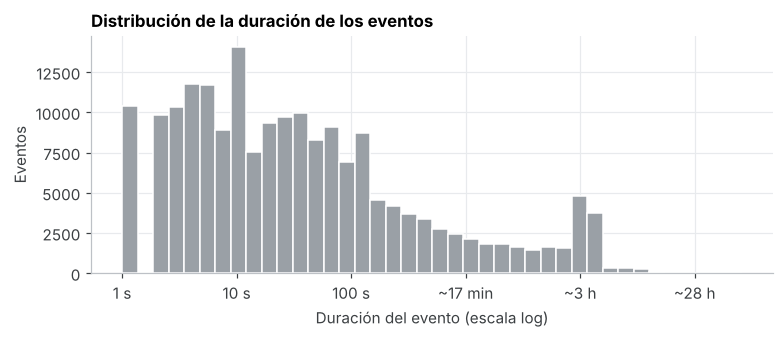

In [23]:
r = eda.resumen_duracion(ev)
display(r["por_evento"])
print("Eventos > 1 h:", r["mayores_1h"], "| > 24 h:", r["mayores_24h"], "| duración cero:", r["duracion_cero"],
      "| fin < inicio:", r["fin_antes_de_inicio"])
display(r["eventos_mayores_24h"])
eda.grafico_duracion(ev)


La duración de los eventos es muy heterogénea (escala log): ralentí y voltaje duran segundos (mediana de 4 a 10 s), mientras que las pérdidas de cobertura GSM/GPRS tienen mediana de 4 a 7 min y una cola de hasta 72 h. El 11 % de los eventos tiene duración cero (marcas puntuales) y ninguno termina antes de empezar, por lo que los tiempos son consistentes. Para el objetivo de la batería, los eventos relevantes son breves: las alertas de voltaje <10 V duran menos de 5 s, y las 71 desconexiones y 90 reinicios de la unidad son instantáneos, así que no permiten medir cuánto dura el problema

### 3.5.4 Ralentí
`EC Ralenti` y `EC Ralenti excesivo` son la única señal de conducción disponible; el motor encendido en ralentí es también contexto para la carga de la batería

,eventos,excesivos,horas_totales,horas_sin_atipicos,% excesivos
AssetExtra,,,,,
VH-01,16582,731,358.6,358.6,4.4
VH-02,32661,1699,1064.5,1064.5,5.2
VH-03,34866,1816,831.0,831.0,5.2
VH-04,43075,1500,853.2,853.2,3.5
VH-05,18017,670,326.4,326.4,3.7


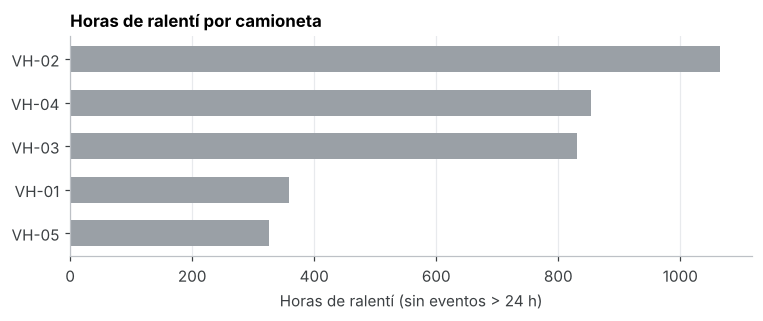

In [24]:
t = eda.resumen_ralenti(ev)
display(t)
eda.grafico_ralenti(t)

Se registran 145.201 eventos de ralentí (≈ 3.434 h), de los cuales el 4,4 % son excesivos pero concentran ≈ 26 % de las horas. Como la telemetría no incluye eventos de conducción, el ralentí es la única señal de motor encendido y se usa como indicador de intensidad de uso

### 3.5.5 Voltaje de la batería (foco del proyecto)

Lecturas: 21,532 | en 0 mV: 658


,count,mean,std,min,25%,50%,75%,max
EventDescription,,,,,,,,
DLP: Alerta Voltaje Bajo Batería (IGNON)<9.5VPro,344.0,6.1,2.52,0.0,6.46,6.91,7.67,9.47
DLP: Alerta Voltaje Batería (IGNON)<10VPro<5s,2299.0,8.78,1.76,0.0,8.27,9.47,9.77,10.37
P.D.C Voltaje Bateria Promedio,18889.0,12.05,2.36,0.0,12.18,12.48,12.93,15.63


Voltaje promedio (sin ceros) por rango: {'< 9 V': 345, '9–11 V': 241, '11–15 V': 17732, '> 15 V': 1}


EventDescription,DLP: Alerta Voltaje Bajo Batería (IGNON)<9.5VPro,DLP: Alerta Voltaje Batería (IGNON)<10VPro<5s,P.D.C Voltaje Bateria Promedio,All
AssetExtra,,,,
VH-01,275,584,3787,4646
VH-02,2,306,3736,4044
VH-03,17,482,4255,4754
VH-04,50,859,5300,6209
VH-05,0,68,1811,1879
All,344,2299,18889,21532


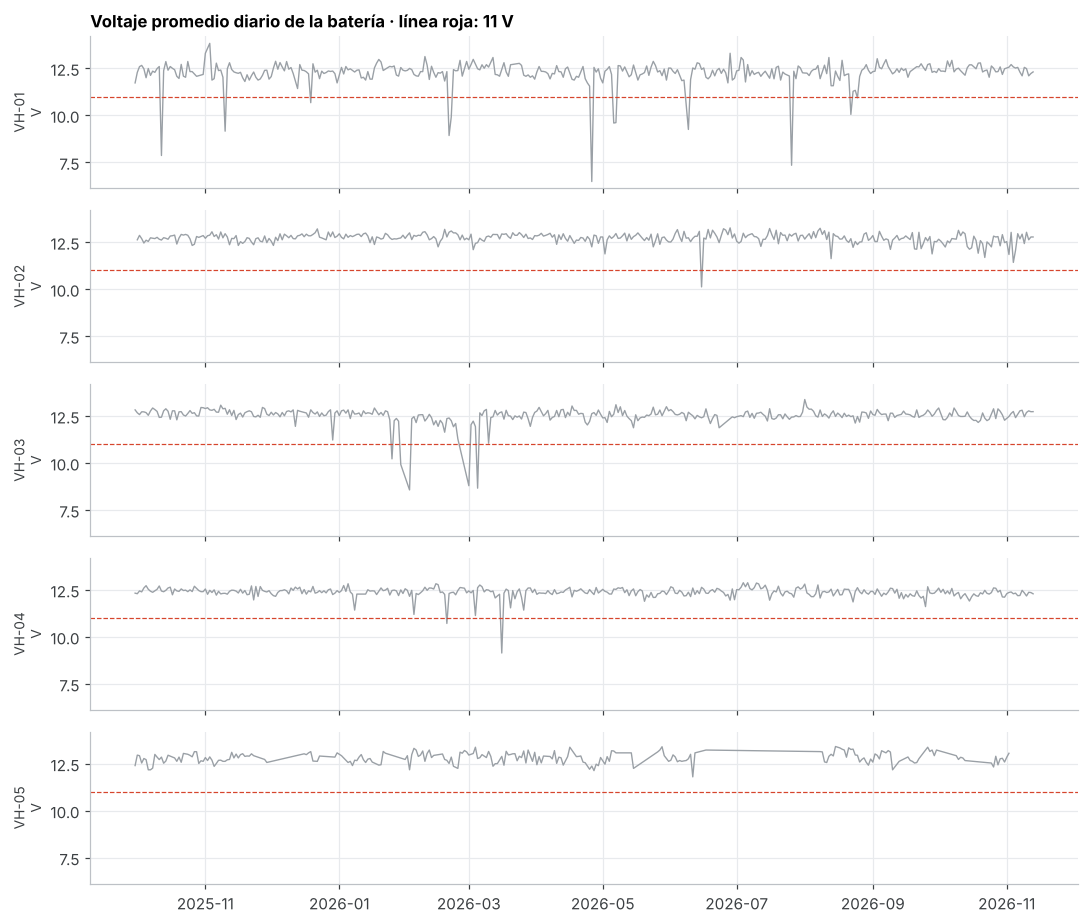

In [25]:
r = eda.resumen_voltaje(ev)
print("Lecturas:", f"{r['lecturas']:,}", "| en 0 mV:", r["en_cero"])
display(r["por_evento"])
print("Voltaje promedio (sin ceros) por rango:", r["rangos_promedio"])
display(r["lecturas_por_camioneta"])
eda.grafico_voltaje_diario(ev)

Se analizan 21.532 lecturas de voltaje: 18.889 promedios periódicos y 2.643 alertas (2.299 de <10 V y 344 de <9,5 V). El 3,1 % (658) está en 0 V (570 en promedios y 88 en alertas) y se trata como dato faltante. Sin esos ceros, el 96,8 % de los promedios cae entre 11 y 15 V con mediana ≈ 12,5 V. Las alertas de <9,5 V tienen mediana de 6,9 V, muy por debajo de su umbral, lo que sugiere caídas profundas que pueden ser descarga severa o artefactos de medición; el 80 % (275 de 344) corresponde a VH-01 y VH-05 no registra ninguna. El número de alertas no refleja el deterioro: VH-04 acumula más alertas de <10 V (859) pero su voltaje diario es estable



### 3.5.6 Odómetro
`StartOdo` sirve para el km/día y para ubicar fallas en el ciclo. Se mide en qué eventos existe y si es coherente (sin retrocesos ni saltos imposibles).

Filas con odómetro > 0: 46,398 (21.8%)
Cobertura por tipo de evento:


,con_odometro,total,pct
EventDescription,,,
DLP: Alerta Voltaje Bajo Batería (IGNON)<9.5VPro,0,344,0.0
DLP: Alerta Voltaje Batería (IGNON)<10VPro<5s,0,2299,0.0
DLP: Desconexion Bateria,71,71,100.0
DLP: No GPRS Coverage,22930,22930,100.0
DLP: No GSM Coverage,23397,23397,100.0
EC Ralenti,0,138785,0.0
EC Ralenti excesivo,0,6416,0.0
OBC unit reset,0,90,0.0
P.D.C Voltaje Bateria Promedio,0,18889,0.0


Cobertura por camioneta:


,con_odometro,total,pct
AssetExtra,,,
VH-01,10907,32167,33.9
VH-02,9870,46586,21.2
VH-03,9246,48898,18.9
VH-04,12340,61629,20.0
VH-05,4035,23941,16.9


Retrocesos del odómetro: 0


,minimo,maximo,lecturas
AssetExtra,,,
VH-01,39922.2,50531.4,10907
VH-02,87472.0,141589.5,9870
VH-03,68784.4,114417.8,9246
VH-04,79618.7,135734.5,12340
VH-05,74797.8,102064.9,4035


Días con lectura: 1635 | pares de días consecutivos: 1610


,count,mean,std,min,25%,50%,75%,max
AssetExtra,,,,,,,,
VH-01,379.0,27.3,25.4,0.0,4.3,23.4,42.5,134.6
VH-02,401.0,135.0,64.8,0.0,85.5,125.0,181.5,312.9
VH-03,388.0,115.7,60.0,0.0,70.8,113.9,157.0,370.5
VH-04,397.0,141.2,69.3,0.0,83.7,142.1,196.4,323.0
VH-05,45.0,112.9,83.1,0.0,54.0,91.0,183.9,268.0


Días con km = 0: 77 | > 500 km/día: 0 | negativos: 0


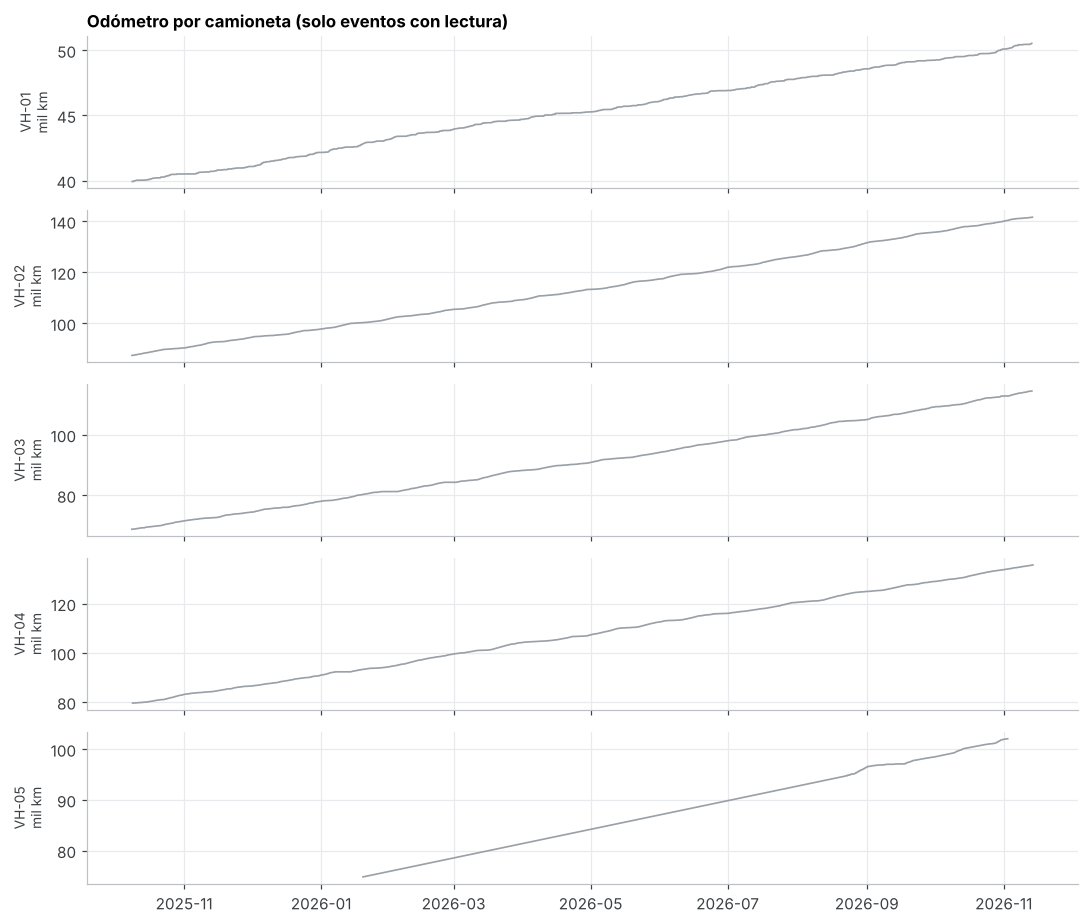

In [26]:
r = eda.resumen_odometro(ev)
print(f"Filas con odómetro > 0: {r['filas_con_odometro']:,} ({r['pct_con_odometro']}%)")
print("Cobertura por tipo de evento:"); display(r["por_evento"])
print("Cobertura por camioneta:"); display(r["por_camioneta"])
print("Retrocesos del odómetro:", r["retrocesos"])
display(r["rango_por_camioneta"])
print(f"Días con lectura: {r['dias_con_lectura']} | pares de días consecutivos: {r['pares_dias_consecutivos']}")
display(r["km_dia_por_camioneta"])
print("Días con km = 0:", r["dias_km_cero"], "| > 500 km/día:", r["dias_mas_500_km"], "| negativos:", r["dias_negativos"])
eda.grafico_odometro(ev)

El odómetro solo se registra en 46.398 filas (21,8 %): todas las pérdidas de cobertura GSM/GPRS y las 71 desconexiones de batería, y ninguna alerta de voltaje ni evento de ralentí. Aun así cubre 1.635 días-camioneta y permite reconstruir el recorrido: es estrictamente creciente (0 retrocesos) y los km diarios son plausibles (máximo 370 km, ningún día negativo ni superior a 500 km; 77 días con 0 km). El uso difiere claramente entre camionetas: VH-04 (≈ 141 km/día), VH-02 (≈ 135) y VH-03 (≈ 116) recorren entre 45.600 y 56.100 km en el periodo, mientras que VH-01 recorre solo ≈ 10.600 km (mediana de 23 km/día y 25 % de los días por debajo de 4 km), coherente con su segmento de uso bajo

### 3.5.7 Conductores

In [27]:
r = eda.resumen_conductores(ev)
print("Conductores distintos:", r["conductores_distintos"])
print(f"Eventos sin conductor identificado: {r['eventos_sin_conductor']:,} ({r['pct_sin_conductor']}%)")
display(r["por_camioneta"])
display(r["top_conductores"])

Conductores distintos: 24
Eventos sin conductor identificado: 0 (0.0%)


,eventos,conductores,pct_sin_conductor
AssetExtra,,,
VH-01,32167,13,0.0
VH-02,46586,12,0.0
VH-03,48898,14,0.0
VH-04,61629,18,0.0
VH-05,23941,11,0.0


,eventos
AssetName2,
Conductor sin identificar,46213
Conductor 07,19637
Conductor 11,19032
Conductor 20,18669
Conductor 21,14631
Conductor 22,14210
Conductor 06,12769
Conductor 19,12457
Conductor 16,12313


Los eventos se asocian a 24 valores distintos de conductor anonimizado (Conductor-NN), pero en 46.213 eventos (21,7 %) el conductor no está identificado. 

Los nueve conductores identificados más frecuentes concentran el 63 % de los eventos (entre ≈ 11.500 y ≈ 19.600 cada uno). Esto implica que el uso de cada camioneta es compartido y que el comportamiento de la batería no puede atribuirse a un conductor

# 4. EDA del Daily Movement Report (viajes)
El reporte de viajes es la fuente directa del uso de cada camioneta (km por viaje, odómetro inicial y final, tiempos). Se usa para el km/día del pronóstico de la fecha del preventivo (OA2) y como variable de contexto de la batería (OA3).

## 4.1 General, completitud y duplicados

In [28]:
vj_raw = eda.leer_viajes(eda.ruta_viajes())
r = eda.resumen_viajes(vj_raw)
print(f"Filas: {r['filas']:,} | columnas: {r['columnas']} | periodo: {r['periodo']} | duplicados: {r['duplicados']}")
print("Vacías:", r["vacias"]); print("Constantes:", r["constantes"])
display(r["viajes_por_camioneta"].to_frame("viajes"))

Filas: 9,589 | columnas: 30 | periodo: 22/05/2026 → 22/10/2026 | duplicados: 9
Vacías: ['FleetNumber', 'TripClassificationComment', 'PassengerList', 'BlankJourneyType']
Constantes: ['SiteName', 'TimeZone1', 'DepartFrom', 'TripType', 'TimeZone2', 'ArriveAt', 'TimeZone', 'NrOfVisits']


,viajes
AssetExtra,
VH-01,1120
VH-02,2287
VH-03,2528
VH-04,2825
VH-05,829


El reporte contiene 9.589 viajes de las 5 camionetas entre el 22/05/2026 y el 22/10/2026 (solo 5 meses, frente a 13,5 meses de eventos). Cuatro columnas están vacías y ocho son constantes (entre ellas `TripType`, siempre "Descalificado", y el origen/destino, que la anonimización generalizó a la región), por lo que se descartan. Hay 9 viajes duplicados (misma camioneta, hora y odómetro) al cierre del reporte, que se eliminan. VH-05 tiene muchos menos viajes que el resto (829), lo que anticipa un problema de cobertura más que de uso.

## 4.2 Días con viajes, sin uso y sin dato
Un día sin viajes puede ser **sin uso** (el odómetro no cambió entre el último viaje y el siguiente) o **sin dato** (el odómetro saltó: hubo viajes que el GPS no reportó). Se distinguen para no imputar 0 km a un día en que la camioneta sí rodó.

,con viajes,sin dato,sin uso,km_dia_media,km_dia_mediana,km_dia_max
placa,,,,,,
VH-01,135,0,19,25.3,23.0,106.0
VH-02,154,0,0,143.9,132.4,307.3
VH-03,147,5,2,121.8,123.6,348.2
VH-04,154,0,0,141.0,140.6,280.8
VH-05,67,80,7,94.7,82.8,281.7


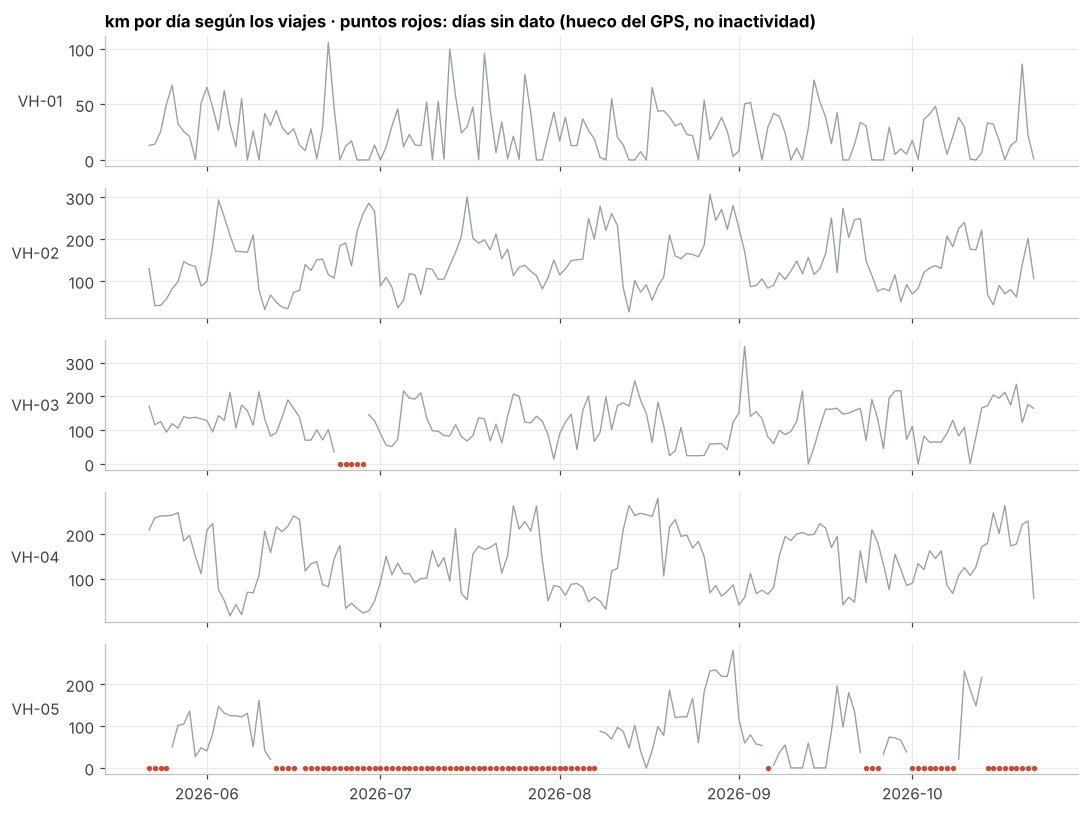

In [29]:
with contextlib.redirect_stdout(io.StringIO()):
    vj = pp.limpiar_viajes(vj_raw)
    vj_dia = pp.agregar_viajes_dia(vj)
display(eda.estado_dias(vj_dia))
eda.grafico_km_dia(vj_dia)

Dentro de cada viaje la distancia coincide con la diferencia del odómetro, pero entre viajes consecutivos hay 7 saltos de odómetro (≈ 6.400 km en total) que corresponden a viajes no reportados. Con esa regla, los días sin viajes se separan en **sin uso** y **sin dato**. VH-02 y VH-04 no tienen días sin dato; VH-01 tiene 19 días sin uso (consistente con su uso bajo), y VH-05 tiene 80 días sin dato, casi todos en un bloque de 51 días (18/06 a 07/08/2026) que coincide con un salto de 4.360 km: es un hueco del GPS, no inactividad. Imputar 0 km en esos días subestimaría su uso. El km/día mediano va de ≈ 23 km (VH-01) a ≈ 141 km (VH-04), lo que confirma que el pronóstico de la fecha del preventivo (OA2) debe hacerse por camioneta.

# 5. Integración de las fuentes
Se ejecuta el preprocesamiento completo (`src/preprocesamiento.py`) para obtener la tabla diaria con las tres fuentes y comparar el uso con la condición de la batería.

In [30]:
with contextlib.redirect_stdout(io.StringIO()):
    _ = pp.main()
diario = pd.read_csv("../data/procesados/tabla_diaria.csv", parse_dates=["fecha"])
print("Sesgo del odómetro GPS frente al km del taller:")
display(pd.read_csv("../docs/factor_odometro.csv"))

Sesgo del odómetro GPS frente al km del taller:


,placa,n,factor,sesgo_pct
0,VH-01,4,1.0127,-1.2581
1,VH-02,10,1.0139,-1.3706
2,VH-03,11,1.0143,-1.4056
3,VH-04,12,1.0067,-0.6628
4,VH-05,2,1.0146,-1.4409


En los días de preventivo, el odómetro GPS queda entre 0,7 % y 1,4 % por debajo del km registrado en el taller, con un sesgo estable dentro de cada camioneta. Se corrige con un factor por camioneta (mediana de km del taller / odómetro GPS). El sesgo es menor que el 2–3 % estimado en la Guía 3 (riesgo 1.2.1), pero sobre un ciclo de 5.000 km equivale a 35–70 km, menos de un día de uso.

## 5.1 Uso frente a alertas de batería

,km_dia_mediana,pct_viajes_cortos,voltaje_mediano_v,alertas_voltaje,desconexiones,km_total,alertas_por_1000km
placa,,,,,,,
VH-01,22.90,51.88,12.34,859.0,29.0,10554.50,81.39
VH-02,124.70,42.43,12.75,308.0,11.0,53975.49,5.71
VH-03,113.60,48.99,12.58,499.0,25.0,45488.80,10.97
VH-04,140.69,44.37,12.40,909.0,4.0,55845.60,16.28
VH-05,87.70,44.27,12.85,68.0,2.0,8476.27,8.02


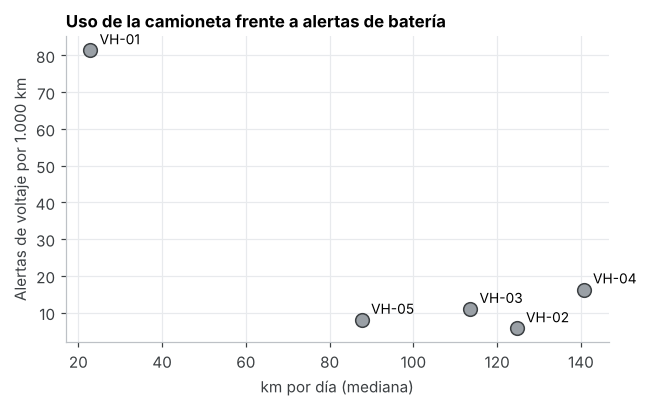

In [31]:
perfil = eda.uso_vs_bateria(diario)
display(perfil)
eda.grafico_uso_vs_bateria(perfil)

VH-01 recorre ≈ 23 km/día (5 a 6 veces menos que el resto), tiene la mayor proporción de viajes cortos (52 %) y registra ≈ 81 alertas de voltaje por cada 1.000 km, entre 5 y 14 veces más que las demás camionetas, además de 29 desconexiones de batería. Es consistente con una batería que no alcanza a recargarse en recorridos cortos. Es una relación observada en 5 camionetas, no una causa probada, y VH-01 no tiene ningún correctivo de batería registrado: puede ser una falla no registrada, un problema de instalación del equipo GPS o una batería débil, lo que debe validarse con el responsable de flota. Para OA3 implica que la señal de voltaje debe compararse con el patrón de uso de cada camioneta, y no con un umbral único para toda la flota.